# 03 — Analisis Univariat
### Milestone M3 (dinilai saat UTS) · Exploratory Data Analysis (KMTI21133)

| | |
|---|---|
| **Nama tim** | _(Bakery Sales)_ |
| **Anggota** | _Alfandi Panca Saputra (0110225026) <br>Muhammad Sultan Ridho (0110225099)<br>Dzakwan Abdur Rasyid (0110225036)<br>Mumtaaz Abdurrahman (0110225164)_ |
| **Topik proyek** | _**Eksplorasi Data Penjualan Bakery**_ |
| **Tanggal** | _(9 November 2026)_ |

**Notebook ini mengisi:** dimensi **Analisis univariat** (20) dan sebagian **Kualitas visualisasi** (15) pada Rubrik M3.

Satu variabel pada satu waktu: bagaimana bentuk distribusinya, berapa sebarannya,
adakah outlier, dan apa artinya bagi pertanyaan analisis Anda.

Yang membedakan nilai 4 dari nilai 2 bukan jumlah grafik, melainkan **tafsirannya**.
Memanggil `describe()` lalu berhenti bernilai 2.

---
> **Sebelum mengumpulkan:** jalankan **Kernel → Restart & Run All**. Notebook yang tidak dapat
> berjalan dari awal sampai akhir dianggap tidak memenuhi dimensi *ketepatan implementasi*.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 60)

plt.rcParams.update({
    'figure.dpi': 110,
    'font.size': 10,
    'axes.titlesize': 11,
    'axes.titleweight': 'bold',
    'axes.grid': True,
    'grid.alpha': 0.25,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
})

DATA = '#0E7490'
SOROT = '#C2410C'
REDUP = '#5B6672'

In [2]:
df = pd.read_csv('/content/data_bersih.csv')

print(f'{df.shape[0]} baris x {df.shape[1]} kolom')

display(df.head())

232795 baris x 8 kolom


,date,time,ticket_number,article,Quantity,unit_price,total_bayar,bulan
0,2021-01-02,08:38,150040,Baguette,1.0,0.90,0.90,2021-01
1,2021-01-02,08:38,150040,Pain Au Chocolat,3.0,1.20,3.60,2021-01
2,2021-01-02,09:14,150041,Pain Au Chocolat,2.0,1.20,2.40,2021-01
3,2021-01-02,09:14,150041,Pain,1.0,1.15,1.15,2021-01
4,2021-01-02,09:25,150042,Traditional Baguette,5.0,1.20,6.00,2021-01


## 0. Variabel mana yang dianalisis, dan mengapa

Jangan menganalisis semua kolom. Pilih yang berkaitan dengan pertanyaan analisis Anda,
lalu sebutkan alasannya.

| Variabel | Tipe | Mengapa relevan dengan pertanyaan kami |
|----------|------|----------------------------------------|
| **Quantity** | Numerik | Mengetahui pola jumlah barang yang dibeli (*basket size*) per item transaksi. |
| **total_bayar** | Numerik | Mengetahui sebaran pengeluaran pelanggan dan seberapa besar kontribusi pesanan bernilai tinggi. |
| **article** | Kategorikal | Mengidentifikasi produk terlaris yang paling banyak menyumbang volume transaksi *bakery*. |
| **bulan** | Kategorikal | Mengamati tren musiman (*seasonality*) dan bulan-bulan dengan penjualan tertinggi. |

## 1. Variabel numerik

Untuk setiap variabel: ringkasan angka, lalu histogram berpasangan dengan boxplot.

In [3]:
NUMERIK = ['Quantity', 'total_bayar']

KATEGORIKAL = ['article', 'bulan']

print("Variabel numerik:", NUMERIK)
print("Variabel kategorikal:", KATEGORIKAL)

print("\nJumlah data kosong:")
print(df[NUMERIK + KATEGORIKAL].isnull().sum())

Variabel numerik: ['Quantity', 'total_bayar']
Variabel kategorikal: ['article', 'bulan']

Jumlah data kosong:
Quantity       1284
total_bayar    1315
article           5
bulan             0
dtype: int64


In [4]:
NUMERIK = ['Quantity', 'total_bayar']

print(df[NUMERIK].describe().T.round(2).to_string())

                count  mean   std   min  25%  50%  75%    max
Quantity     231511.0  1.56  1.20  1.00  1.0  1.0  2.0  200.0
total_bayar  231480.0  2.43  2.57  0.07  1.2  1.6  2.6  200.0


In [5]:
import matplotlib as _mpl

_V = tuple(int(x) for x in _mpl.__version__.split('.')[:2])

ARAH = {'orientation': 'horizontal'} if _V >= (3, 10) else {'vert': False}

def potret(kolom, satuan=''):
    d = df[kolom].dropna()

    q1, q3 = d.quantile([0.25, 0.75])
    iqr = q3 - q1

    bawah = q1 - 1.5 * iqr
    atas = q3 + 1.5 * iqr

    z = (d - d.mean()).abs() / d.std()

    fig, ax = plt.subplots(
        2, 1,
        figsize=(7.2, 4.2),
        sharex=True,
        layout='constrained',
        gridspec_kw={'height_ratios': [3, 1]}
    )

    ax[0].hist(
        d,
        bins=32,
        color=DATA,
        edgecolor='white',
        linewidth=0.6
    )

    ax[0].set_ylabel('Frekuensi')
    ax[0].set_title(f'{kolom} (n = {len(d)})')

    ax[1].boxplot(
        d,
        **ARAH,
        widths=0.55,
        patch_artist=True,
        boxprops=dict(
            facecolor='#CFE8EF',
            edgecolor='#16202B'
        ),
        medianprops=dict(
            color=SOROT,
            linewidth=2
        ),
        flierprops=dict(
            marker='o',
            markersize=4,
            markerfacecolor=DATA,
            markeredgecolor='none',
            alpha=0.6
        )
    )

    ax[1].set_yticks([])
    ax[1].set_xlabel(f'{kolom} {satuan}'.strip())

    plt.show()

    print(f'Mean       : {d.mean():.2f}')
    print(f'Median     : {d.median():.2f}')
    print(f'Selisih    : {d.mean()-d.median():+.2f}')
    print(f'Std        : {d.std():.2f}')
    print(f'IQR        : {iqr:.2f}')
    print(f'Skewness   : {stats.skew(d):.3f}')

    print(
        f'Outlier IQR: {((d < bawah) | (d > atas)).sum()} '
        f'(batas {bawah:.2f} sampai {atas:.2f})'
    )

    print(f'Outlier Z  : {(z > 3).sum()}')

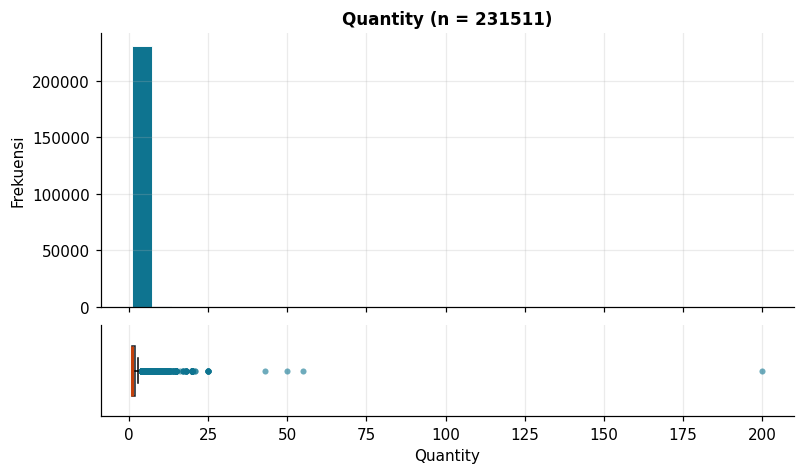

Mean       : 1.56
Median     : 1.00
Selisih    : +0.56
Std        : 1.20
IQR        : 1.00
Skewness   : 23.615
Outlier IQR: 12954 (batas -0.50 sampai 3.50)
Outlier Z  : 3121


In [6]:
potret('Quantity')

**Tafsiran Variabel 1 (Quantity)**

Distribusi variabel `Quantity` sangat condong ke kanan (*right-skewed*). Hal ini ditunjukkan oleh ekor distribusi yang memanjang ke arah kanan dan nilai *skewness* yang tinggi, yaitu 23,61. Berdasarkan hasil statistik, nilai *median* sebesar 1,0 menunjukkan bahwa jumlah barang yang paling mewakili pola umum adalah 1 barang per catatan penjualan. Sementara itu, nilai *mean* sebesar 1,56 lebih tinggi karena dipengaruhi oleh beberapa catatan penjualan dengan jumlah barang yang jauh lebih besar, bahkan mencapai 200 barang. Oleh karena itu, median lebih tepat digunakan untuk menggambarkan nilai pemusatan data `Quantity` karena tidak terlalu terpengaruh oleh nilai ekstrem.

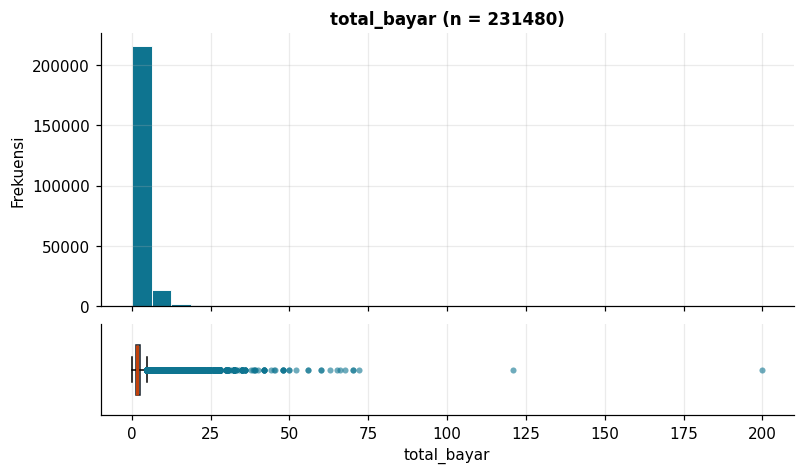

Mean       : 2.43
Median     : 1.60
Selisih    : +0.83
Std        : 2.57
IQR        : 1.40
Skewness   : 6.587
Outlier IQR: 27531 (batas -0.90 sampai 4.70)
Outlier Z  : 3922


In [7]:
potret('total_bayar')

**Tafsiran Variabel 2 (total_bayar).** Distribusi variabel `total_bayar` sangat condong ke kanan (*right-skewed*), dibuktikan dengan ekor boxplot yang memanjang ke kanan serta nilai *skewness* sebesar 6.59. Berdasarkan hasil statistik, nilai *mean* sebesar 2.43 lebih tinggi dibandingkan nilai *median* sebesar 1.60. Hal ini menunjukkan bahwa terdapat beberapa catatan penjualan dengan nilai pembayaran yang jauh lebih besar sehingga memengaruhi rata-rata. Oleh karena itu, **median** lebih tepat digunakan untuk menggambarkan nilai pembayaran yang tipikal karena tidak terlalu terpengaruh oleh nilai-nilai ekstrem.

## 2. Keputusan tentang outlier

Outlier tidak otomatis dibuang. Pemeriksaan dilakukan terlebih dahulu untuk mengetahui apakah nilai ekstrem tersebut masih masuk akal dalam konteks transaksi bakery.

| Variabel | Metode yang dipakai | Jumlah | Sah atau keliru? | Tindakan dan alasan |
|----------|---------------------|--------|------------------|---------------------|
| **Quantity** | Batas IQR (> 3.5) | 12.954 | Sebagian besar dianggap sah | **Dipertahankan**. Jumlah barang yang tinggi masih mungkin terjadi dalam transaksi bakery, misalnya pembelian dalam jumlah besar. Data akan ditandai untuk analisis lanjutan. |
| **total_bayar** | Batas IQR (> 4.7) | 27.531 | Sebagian besar dianggap sah | **Dipertahankan**. Nilai pembayaran yang tinggi masih mungkin terjadi karena pembelian dengan jumlah barang lebih banyak atau produk dengan harga lebih tinggi. |

**Catatan:** Batas bawah IQR menghasilkan nilai negatif, yaitu -0.5 untuk `Quantity` dan -0.9 untuk `total_bayar`. Karena kedua variabel tersebut tidak memiliki nilai negatif pada data yang dianalisis, pemeriksaan outlier menggunakan batas atas saja.

In [8]:
# Menghitung batas atas IQR untuk Quantity
q1, q3 = df['Quantity'].quantile([0.25, 0.75])
iqr_q = q3 - q1
atas_q = q3 + 1.5 * iqr_q

# Menghitung batas atas IQR untuk total_bayar
t1, t3 = df['total_bayar'].quantile([0.25, 0.75])
iqr_t = t3 - t1
atas_t = t3 + 1.5 * iqr_t

# Menandai data outlier tanpa menghapusnya
df['outlier_quantity'] = df['Quantity'] > atas_q
df['outlier_total_bayar'] = df['total_bayar'] > atas_t

# Menampilkan hasil perhitungan
print("HASIL DETEKSI OUTLIER")
print("=" * 45)

print(f"Quantity:")
print(f"Batas atas IQR : {atas_q:.2f}")
print(f"Jumlah outlier : {df['outlier_quantity'].sum():,}")

print("\ntotal_bayar:")
print(f"Batas atas IQR : {atas_t:.2f}")
print(f"Jumlah outlier : {df['outlier_total_bayar'].sum():,}")

HASIL DETEKSI OUTLIER
Quantity:
Batas atas IQR : 3.50
Jumlah outlier : 12,954

total_bayar:
Batas atas IQR : 4.70
Jumlah outlier : 27,531


## 3. Variabel kategorikal

In [9]:
KATEGORIKAL = ['article', 'bulan']

for k in KATEGORIKAL:
    vc = df[k].value_counts()

    total_valid = df[k].notna().sum()

    hasil = pd.DataFrame({
        'jumlah': vc,
        'persen': (vc / total_valid * 100).round(2)
    })

    print(f'\n{k} ({df[k].nunique()} nilai unik)')
    print(f'Total data valid: {total_valid:,}')
    print(hasil.head(12).to_string())


article (148 nilai unik)
Total data valid: 232,790
                      jumlah  persen
article                             
Traditional Baguette   67605   29.04
Coupe                  19618    8.43
Baguette               15281    6.56
Banette                15117    6.49
Croissant              11486    4.93
Pain Au Chocolat       10564    4.54
Special Bread           5184    2.23
Cereal Baguette         4950    2.13
Formule Sandwich        4191    1.80
Boule 400G              4084    1.75
Campagne                3894    1.67
Complet                 3133    1.35

bulan (21 nilai unik)
Total data valid: 232,795
         jumlah  persen
bulan                  
2021-08   20194    8.67
2022-08   20040    8.61
2022-07   18160    7.80
2021-07   17475    7.51
2021-05   12155    5.22
2022-05   11819    5.08
2021-04   10841    4.66
2021-06   10806    4.64
2022-06   10640    4.57
2021-09   10157    4.36
2022-04   10081    4.33
2021-10    9817    4.22


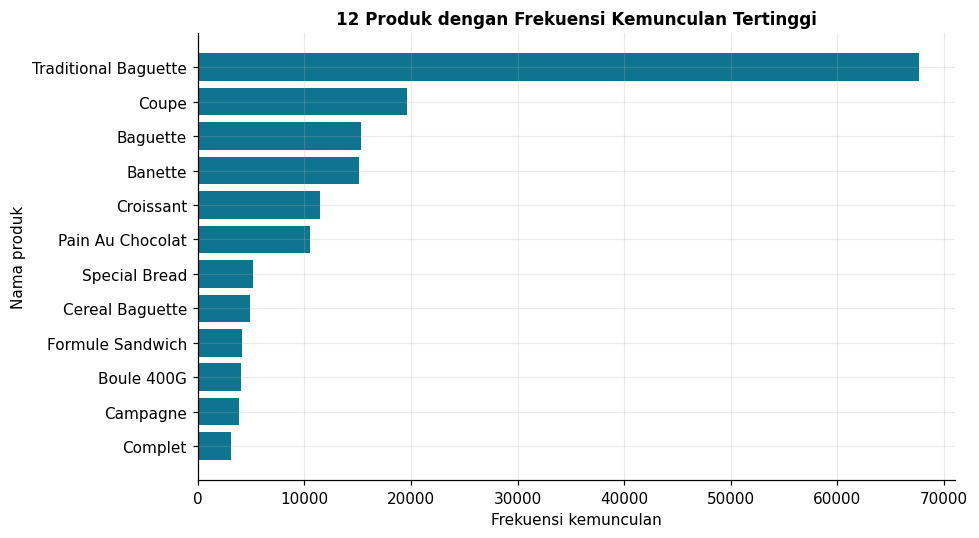

In [10]:
k = 'article'

vc = df[k].value_counts().head(12)

fig, ax = plt.subplots(figsize=(9, 5))

ax.barh(
    vc.index[::-1],
    vc.values[::-1],
    color=DATA
)

ax.set_xlabel('Frekuensi kemunculan')
ax.set_ylabel('Nama produk')
ax.set_title('12 Produk dengan Frekuensi Kemunculan Tertinggi')

plt.tight_layout()
plt.show()

**Tafsiran Variabel 3 (article).**

Berdasarkan grafik 12 produk dengan frekuensi kemunculan tertinggi, terlihat bahwa produk Traditional Baguette sangat mendominasi dengan jumlah kemunculan sekitar 67.000 kali. Jumlah tersebut jauh lebih tinggi dibandingkan produk lainnya, seperti Coupe yang berada di posisi kedua dengan sekitar 19.000 kemunculan. Produk lain yang juga cukup sering muncul adalah Baguette, Banette, Croissant, dan Pain Au Chocolat.

Hal ini menunjukkan bahwa penjualan bakery didominasi oleh beberapa jenis produk tertentu, terutama Traditional Baguette. Sementara itu, produk lainnya memiliki frekuensi kemunculan yang lebih rendah. Pola ini menunjukkan adanya distribusi kategori produk yang tidak merata, dengan beberapa produk memiliki popularitas jauh lebih tinggi dibandingkan produk lainnya.

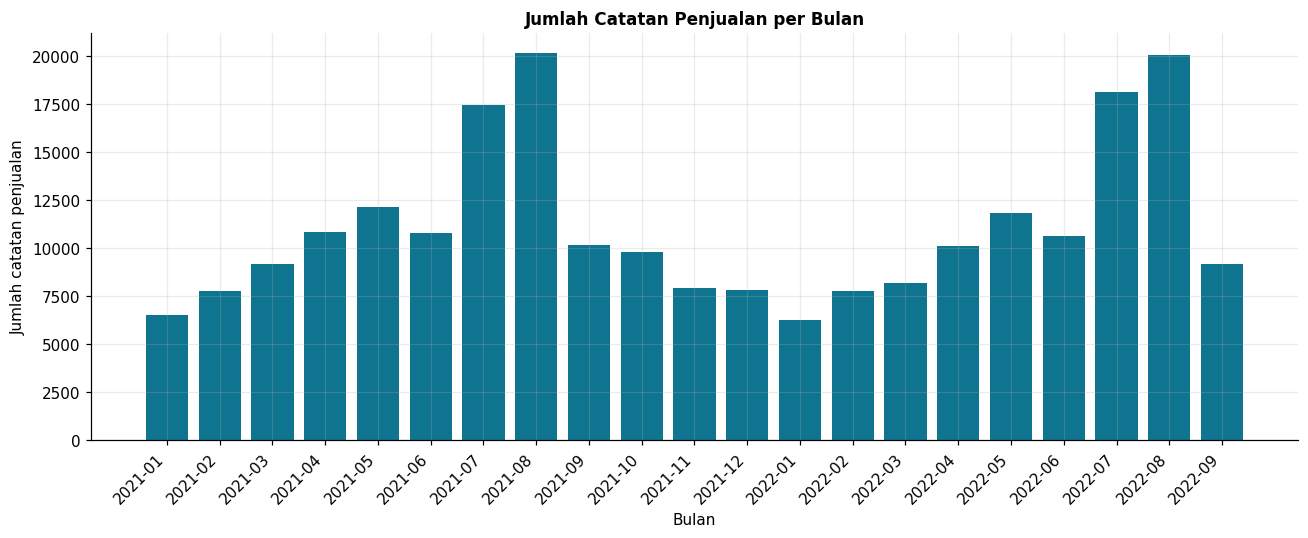

In [11]:
k = 'bulan'

vc = df[k].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(12, 5))

ax.bar(
    vc.index,
    vc.values,
    color=DATA
)

ax.set_xlabel('Bulan')
ax.set_ylabel('Jumlah catatan penjualan')
ax.set_title('Jumlah Catatan Penjualan per Bulan')

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Tafsiran Variabel 4 (bulan).**

Berdasarkan grafik jumlah catatan penjualan per bulan, terlihat bahwa jumlah penjualan mengalami fluktuasi selama periode Januari 2021 hingga September 2022. Jumlah catatan penjualan tertinggi terlihat pada Agustus 2021 dan Agustus 2022, dengan masing-masing mencapai sekitar 20.000 catatan. Sementara itu, jumlah terendah terlihat pada Januari 2022, yaitu sekitar 6.000 catatan.

Pada beberapa bulan, seperti Juli dan Agustus, jumlah catatan penjualan cenderung mengalami peningkatan. Namun, setelah mencapai puncaknya, jumlah tersebut kembali menurun pada bulan-bulan berikutnya. Hal ini menunjukkan bahwa aktivitas penjualan bakery mengalami perubahan dari waktu ke waktu dan tidak memiliki jumlah yang stabil setiap bulannya.

**Kesimpulan Variabel Kategorikal**

Berdasarkan hasil analisis, variabel `article` menunjukkan bahwa Traditional Baguette merupakan produk yang paling sering muncul dalam catatan penjualan. Sementara itu, variabel `bulan` menunjukkan bahwa jumlah catatan penjualan mengalami fluktuasi selama periode pengamatan, dengan jumlah tertinggi terjadi pada Agustus 2021 dan Agustus 2022. Dengan demikian, kedua variabel kategorikal memberikan gambaran mengenai produk yang paling sering tercatat dan perubahan aktivitas penjualan setiap bulannya.

## 4. Ringkasan Temuan Univariat

| Variabel | Bentuk distribusi | Pemusatan yang dipakai | Outlier | Catatan untuk analisis berikutnya |
|----------|-------------------|------------------------|---------|-----------------------------------|
| **Quantity** | Menjulur ke kanan (*right-skewed*) | Median (1,0) | Banyak di ekor kanan | Perlu dilakukan pemeriksaan lebih lanjut terhadap catatan penjualan dengan jumlah barang yang sangat besar untuk membedakan pembelian biasa dan kemungkinan pesanan grosir. |
| **total_bayar** | Menjulur ke kanan (*right-skewed*) | Median (1,6) | Banyak di ekor kanan | Perlu ditelusuri produk atau transaksi yang menyebabkan nilai pembayaran sangat tinggi. |
| **article** | *Pareto* / *Long-tail* | Modus (Traditional Baguette) | - | Produk dengan frekuensi kemunculan rendah dapat digabungkan ke kategori `Lain-lain` agar analisis berikutnya lebih mudah dibaca. |
| **bulan** | Fluktuatif dengan dua puncak utama | Modus (Agustus) | - | Perlu ditelusuri lebih lanjut penyebab peningkatan jumlah catatan penjualan pada Juli dan Agustus. |

## Checklist sebelum mengumpulkan

- [x] Setiap variabel yang dianalisis memiliki tafsiran, bukan hanya grafik.
- [x] Bentuk distribusi dinyatakan dengan bukti dari gambar **dan** dari angka.
- [x] Pilihan mean atau median disertai alasan.
- [x] Keputusan tentang outlier dicatat beserta alasannya; tidak ada yang dibuang tanpa diperiksa.
- [x] Setiap grafik memiliki judul, label sumbu, dan satuan.
- [x] n yang dilaporkan adalah n setelah `dropna()`.
- [x] Restart & Run All berjalan tanpa galat.